# Fashion Assistant: Data Processing and Insights

## Import Libraries and Inpect Data

In [1]:
import pandas as pd
import numpy as np
import re
import random
import spacy
pd.set_option('display.max_columns', None)  
pd.set_option('display.max_rows', None)     
pd.set_option('display.width', None)   

In [2]:
df = pd.read_json('flipkart_fashion_products_dataset.json')

df.head()


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Men Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


In [3]:
df.info()
# there are many object types, see the actual type, are there any mixed types in any feature?

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   _id              30000 non-null  object        
 1   actual_price     30000 non-null  object        
 2   average_rating   30000 non-null  object        
 3   brand            30000 non-null  object        
 4   category         30000 non-null  object        
 5   crawled_at       30000 non-null  datetime64[ns]
 6   description      30000 non-null  object        
 7   discount         30000 non-null  object        
 8   images           30000 non-null  object        
 9   out_of_stock     30000 non-null  bool          
 10  pid              30000 non-null  object        
 11  product_details  30000 non-null  object        
 12  seller           30000 non-null  object        
 13  selling_price    30000 non-null  object        
 14  sub_category     30000 non-null  objec

In [4]:
# keep a copy of raw df just in case
df_copy= df.copy()

In [5]:
def column_info(df):
    """Summarize the key information for each column in the given DataFrame (`df`). """
    info_df = pd.DataFrame(columns=['Column_name', 'Data_Type', 'Count', 'NaN_Count', 'Unique_Count', 'max_value', 'min_value', 'sample_value'])
    for col in df.columns:
        data_type = df[col].dtype
        count = df[col].count()
        nan_count = df[col].isnull().sum()
        unique_count = df[col].nunique()
        if pd.api.types.is_numeric_dtype(df[col]):
            max_value = df[col].max()
            min_value = df[col].min()
            non_nan_values = df[col].dropna().unique().tolist()
            random_value = random.choice(non_nan_values) if non_nan_values else None
            info_df = info_df._append({'Column_name': col, 'Data_Type': data_type, 'Count': count, 'NaN_Count': nan_count, 'Unique_Count': unique_count,
                                      'max_value': max_value,
                                      'min_value': min_value,
                                      'sample_value': random_value}, ignore_index=True)
        else:
            sample_values = df[col].dropna().unique().tolist()
            info_df = info_df._append({'Column_name': col, 'Data_Type': data_type, 'Count': count, 'NaN_Count': nan_count, 'Unique_Count': unique_count,
                                      'max_value': 'no value',
                                      'min_value': 'no value',
                                      'sample_value': random.choice(sample_values) if sample_values else None}, ignore_index=True)
    return info_df

In [6]:
# check the numeric values min max to prevent discreparancies, first convert str into numeric and store in temp columns
# The reason is, I want to keep my columns as str for now, since converting to int might cause Nan values pop up.
df['actual_price_temp'] = pd.to_numeric(df['actual_price'], errors='coerce')
df['selling_price_temp'] = pd.to_numeric(df['selling_price'], errors='coerce')
df['average_rating_temp'] = pd.to_numeric(df['average_rating'], errors='coerce')

In [7]:
df_= df.drop(["product_details","images","actual_price", "selling_price", "average_rating"], axis= 1)
column_info(df_)
# everything seems reasonable. Price range is quite wide, but it is possible

,Column_name,Data_Type,Count,NaN_Count,Unique_Count,max_value,min_value,sample_value
0,_id,object,30000,0,30000,no value,no value,78faf73a-e9cc-5d81-af24-12fc1a0206a6
1,brand,object,30000,0,325,no value,no value,Zen
2,category,object,30000,0,4,no value,no value,Clothing and Accessories
3,crawled_at,datetime64[ns],30000,0,17188,no value,no value,2021-02-10 22:57:14
4,description,object,30000,0,5194,no value,no value,TRIPIN ORANGE AND SILVER CUFFLINK FOR MEN WITH...
5,discount,object,30000,0,88,no value,no value,23% off
6,out_of_stock,bool,30000,0,2,True,False,True
7,pid,object,30000,0,28080,no value,no value,TSHFHG6G7PN3NTHA
8,seller,object,30000,0,535,no value,no value,ATTIITUDE
9,sub_category,object,30000,0,24,no value,no value,Winter Wear


In [8]:
# drop the temporary columns
df.drop(['actual_price_temp','selling_price_temp','average_rating_temp'], axis=1, inplace=True)

In [9]:
def inspect_column_types_and_unique_counts(df):
    """
    Inspect the unique types and counts of unique types per column in a DataFrame.

    """
    results = []

    for col in df.columns:
        unique_types = df[col].map(type).nunique()  
        unique_type_names = df[col].map(type).unique()  
        
        results.append({
            "Column": col,
            "Data_Types": ", ".join([str(t) for t in unique_type_names]), 
            "Unique_Types_Count": unique_types 
        })

    type_inspection_df = pd.DataFrame(results)
    return type_inspection_df

type_inspection = inspect_column_types_and_unique_counts(df)
type_inspection
# all the objects are str type, apart from product_description and images(they are lists)

,Column,Data_Types,Unique_Types_Count
0,_id,<class 'str'>,1
1,actual_price,<class 'str'>,1
2,average_rating,<class 'str'>,1
3,brand,<class 'str'>,1
4,category,<class 'str'>,1
5,crawled_at,<class 'pandas._libs.tslibs.timestamps.Timesta...,1
6,description,<class 'str'>,1
7,discount,<class 'str'>,1
8,images,<class 'list'>,1
9,out_of_stock,<class 'bool'>,1


In [10]:
df.columns
# inspected column names to be able to call them properly

Index(['_id', 'actual_price', 'average_rating', 'brand', 'category',
       'crawled_at', 'description', 'discount', 'images', 'out_of_stock',
       'pid', 'product_details', 'seller', 'selling_price', 'sub_category',
       'title', 'url'],
      dtype='object')

In [11]:
# Nested features excluded to enable using duplicated method, looks like no duplicates
print(f'Shape is {df.shape} \nDuplicates: {df.drop(["product_details","images"], axis=1).duplicated().sum()}')

Shape is (30000, 17) 
Duplicates: 0


In [12]:
# no nulls indicated above, see if there is any empty str
df_=df.drop(["product_details","images"], axis=1) #drop the list type features, they will be seperately inspected

empty_string_count = (df_.map(lambda x: x == "")).sum().sum()

print(f"Total number of empty strings in the entire dataset: {empty_string_count}")

Total number of empty strings in the entire dataset: 20041


In [13]:
def count_empty_strings_per_column(df):
    """
    Count the number of empty strings in each object-type column of a DataFrame.

    """
    empty_strings_per_column = {}

    for column in df.columns:
        if df[column].dtype == 'object':  
            empty_count = (df[column] == "").sum()  
            empty_strings_per_column[column] = empty_count

    return empty_strings_per_column

empty_strings = count_empty_strings_per_column(df)

for column, count in empty_strings.items():
    print(f"Column '{column}' has {count} empty strings")
# produc details and images will be counted seperately, ignore them

Column '_id' has 0 empty strings
Column 'actual_price' has 863 empty strings
Column 'average_rating' has 2446 empty strings
Column 'brand' has 2068 empty strings
Column 'category' has 0 empty strings
Column 'description' has 11980 empty strings
Column 'discount' has 941 empty strings
Column 'images' has 0 empty strings
Column 'pid' has 0 empty strings
Column 'product_details' has 0 empty strings
Column 'seller' has 1741 empty strings
Column 'selling_price' has 2 empty strings
Column 'sub_category' has 0 empty strings
Column 'title' has 0 empty strings
Column 'url' has 0 empty strings


## Data Preprocessing

In [14]:
# If pid is unique for the same product, the corresponding features also should be same( seller might be different but product features will be same)
# Group by 'pid' and check the number of unique 'brand'  values in each group, to verify the assumption
pid_group_check = df.groupby('pid').agg({
    'brand': lambda x: x.nunique()
})
# Filter for inconsistent groups where there is more than 1 unique value for 'brand'
inconsistent_pids = pid_group_check[pid_group_check['brand'] > 1]

print("Inconsistent 'pid' groups based on 'brand':")
print(inconsistent_pids)

#all the pids fit the assumption above, except for one

Inconsistent 'pid' groups based on 'brand':
                  brand
pid                    
TSHFWVYDD2G5USN6      2


In [15]:
df[df["pid"]=="TSHFWVYDD2G5USN6"]
# seemed incossistent because the brand name was empty idx:18298
# manual inspection shows every observation is the same in all rows, except for Id. 

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
18249,c4605625-00c7-5acf-b4be-b4e70ae16140,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:04,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18267,d08decd0-ac26-53f0-b002-e7ed5da968a5,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:25,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18287,8e677a4d-1ef7-528a-99d4-84abeadbda69,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:42,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18288,55b76c00-e19b-5d9e-b699-f95d01974faf,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:43,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18289,b9ebac4c-4f58-5927-841a-a858c99f7fdb,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:43,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18290,46210551-48b3-5820-884a-530b8c32715e,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:44,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18291,cb222303-906b-5d5e-86a1-51d3f5c3411f,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:45,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18292,8233bebb-62bf-5f24-8ef9-33f21a8727e7,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:46,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18293,a8569cb7-4ad1-5935-9055-206393572c88,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:47,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",ONEIRO CONCEPTS,378,Topwear,Solid Men Polo Neck Maroon T-Shirt,https://www.flipkart.com/oneiro-solid-men-polo...
18294,ce0db586-bf15-5910-8cc1-caaa04cef054,999,4.5,Onei,Clothing and Accessories,2021-02-10 23:34:48,Refresh your clothing with the awesome collect...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFWVYDD2G5USN6,"[{'Type': 'Polo Neck'}, {'Slee

In [16]:
# Display full image URLs for the given row where 'pid' matches
selected_rows = df[df["pid"] == "TSHFWVYDD2G5USN6"][["images"]]

for index, row in selected_rows.iterrows():
    if isinstance(row["images"], list):  
        print(f"Row {index}:")
        for url in row["images"]:
            print(url)
        print("\n")  
    else:
        print(f"Row {index} does not contain a list of URLs.\n")
# despite different ids, all the produts are same. They are duplicates. Make sure to drop id before checking again

Row 18249:
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/o/m/k/m-polo-solid-men-wine-oneiro-original-imafwvybphezshgd.jpeg?q=70
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/n/2/6/m-polo-solid-men-wine-oneiro-original-imafwvyb5wwmj4zq.jpeg?q=70
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/k/q/2/m-polo-solid-men-wine-oneiro-original-imafwvybn7uz7u5n.jpeg?q=70
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/n/f/o/m-polo-solid-men-wine-oneiro-original-imafwvybgvzfgzgq.jpeg?q=70
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/p/f/l/m-polo-solid-men-wine-oneiro-original-imafwvybuqnckp7t.jpeg?q=70
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/n/m/k/m-polo-solid-men-wine-oneiro-original-imafwvybhrqndk7x.jpeg?q=70


Row 18267:
https://rukminim1.flixcart.com/image/128/128/kgpg5u80-0/t-shirt/o/m/k/m-polo-solid-men-wine-oneiro-original-imafwvybphezshgd.jpeg?q=70
https://rukminim1.flixcart.com/

In [17]:
# Inspect URL's to double check, since they are unique by name but should be same by content for the same pid
pd.set_option('display.max_colwidth', None)  # No truncation for column content

selected_rows = df[df["pid"] == " in FWVYDD2G5USN6"][["url"]]
selected_rows

,url
18249,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_1_25&otracker=browse&fm=organic&iid=6eeaadec-ba88-4202-9aff-a1dbeeb904db.TSHFWVYDD2G5USN6.SEARCH&ssid=nd3tfm51z40000001612116847870
18267,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_2_44&otracker=browse&fm=organic&iid=en_ZtB%2FX3N7%2BnNodr6yzqq000R4IJdk9S%2B1erPtPjYUiF231imvmXctpEKBU3Ap74lcNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=5j4aaraj000000001612116849280
18287,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_3_81&otracker=browse&fm=organic&iid=en_3hli2KvaywxqLtopOdn3cZC0zziGjQ8dl03qhk1XsYC7cCtdqkgRpwxIkhEqHpl4NXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=gv81yl15740000001612116850127
18288,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_4_121&otracker=browse&fm=organic&iid=en_Jz%2Bv5POrwLDkgLk5uZrsC95zle20jZtU8hlhq7RFA%2Fg%2B5L3kYAjVKeEkdfBTp%2FORNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=83kbgym0io0000001612116852557
18289,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_5_161&otracker=browse&fm=organic&iid=en_ucW0hbT88grFDSlWLCqr42UqUOMeNnOXlZkclRX5Sidm4%2B6QC1oNCq613xBqNdfPNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=ziaruwgd8g0000001612116852960
18290,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_6_201&otracker=browse&fm=organic&iid=en_R%2BdSc96FZAcMqLvnTaontSQhMrrwUR0pc62qShiU9hm%2FooXyjYKXtG1AJ%2BIAwGeoNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=msbzoigqkw0000001612116853515
18291,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_7_241&otracker=browse&fm=organic&iid=en_zn9zr9buavYDEIjNDM5gd087aMDhcF5QsDD9WfnKkYz7LrFpp0qg89t%2B5JIMgxlxNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=j87pao59hc0000001612116854659
18292,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_8_281&otracker=browse&fm=organic&iid=en_51AiSMmUw1Wa29FDIFLpy2rZYpeuRzGaodtUBxERii8wjwHmdga%2Fg1W5aLptRAdlNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=1sffkrtwow0000001612116855522
18293,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_9_321&otracker=browse&fm=organic&iid=en_uReFGoIF%2FTcOzC3EW6%2FoR43LmlNBKZheFhx%2Bmvz8eiFtNs6NnBLn3BbQqVtf8PFLNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=k1pztv5ao00000001612116856335
18294,https://www.flipkart.com/oneiro-solid-men-polo-neck-maroon-t-shirt/p/itm77621254b36de?pid=TSHFWVYDD2G5USN6&lid=LSTTSHFWVYDD2G5USN6RRQ5ZA&marketplace=FLIPKART&srno=b_10_361&otracker=browse&fm=organic&iid=en_Bw8xxT7rvi5aCLzNs%2FWTMDWogYXn7E8cX7e5I3LAfkgVVvGP6VuzFD1YEwABmHsdNXCiY6a1vOj6U0zDWaaMfg%3D%3D&ssid=mahd3seiao0000001612116861122


In [18]:
# quick manual inspection to see if the product desciption is also same in the duplicates. Images were already checked above.
df[df["pid"]=="TSHFWVYDD2G5USN6"]["product_details"].sample(2)

18300    [{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleeve'}, {'Fit': 'Regular'}, {'Fabric': 'Pure Cotton'}, {'Sales Package': '1 Tshirt'}, {'Pack of': '1'}, {'Style Code': 'polo solid men wine'}, {'Neck Type': 'Polo Neck'}, {'Ideal For': 'Men'}, {'Size': 'M'}, {'Pattern': 'Solid'}, {'Suitable For': 'Western Wear'}, {'Fabric Care': 'Gentle Machine Wash'}, {'Model Name': 'Mens Regular Fit Cotton Polo T-Shirt'}, {'Brand Color': 'Wine'}, {'Generic Name': 'T Shirts'}, {'Country of Origin': 'India'}]
18301    [{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleeve'}, {'Fit': 'Regular'}, {'Fabric': 'Pure Cotton'}, {'Sales Package': '1 Tshirt'}, {'Pack of': '1'}, {'Style Code': 'polo solid men wine'}, {'Neck Type': 'Polo Neck'}, {'Ideal For': 'Men'}, {'Size': 'M'}, {'Pattern': 'Solid'}, {'Suitable For': 'Western Wear'}, {'Fabric Care': 'Gentle Machine Wash'}, {'Model Name': 'Mens Regular Fit Cotton Polo T-Shirt'}, {'Brand Color': 'Wine'}, {'Generic Name': 'T Shirts'}, {'Country of Origin': 'India'}]
Na

In [19]:
pd.reset_option('display.max_colwidth') #set back to the original setting

In [20]:
df["_id"].nunique() #id is just a unique number for every observation, can be dropped. Then check the duplicates again.

30000

In [21]:
df.drop(["_id"], axis=1, inplace=True)

In [22]:
df.columns

Index(['actual_price', 'average_rating', 'brand', 'category', 'crawled_at',
       'description', 'discount', 'images', 'out_of_stock', 'pid',
       'product_details', 'seller', 'selling_price', 'sub_category', 'title',
       'url'],
      dtype='object')

In [23]:
# date column is also unique and should be dropped to check. URLs are also different because of different scraping times
print(f'\nDuplicates: {df.drop(["product_details","images","crawled_at","url"], axis=1).duplicated().sum()}')


Duplicates: 1911


In [24]:
# now safely drop duplicates as inspection completed
columns_to_exclude = ["product_details", "images", "crawled_at", "url"]
columns_to_check = [col for col in df.columns if col not in columns_to_exclude]
df = df.drop_duplicates(subset=columns_to_check, keep='first')

print(f"Number of rows after dropping duplicates: {len(df)}")


Number of rows after dropping duplicates: 28089


In [25]:
df.shape 

(28089, 16)

In [26]:
empty_strings_after_cleaning = count_empty_strings_per_column(df)

for column, count in empty_strings_after_cleaning.items():
    print(f"Column '{column}' has {count} empty strings")

# now pid can actually be used to fill in brand names?(I realized that I oversight here, as pids are almost unique across all rows)

Column 'actual_price' has 778 empty strings
Column 'average_rating' has 2261 empty strings
Column 'brand' has 2011 empty strings
Column 'category' has 0 empty strings
Column 'description' has 11152 empty strings
Column 'discount' has 856 empty strings
Column 'images' has 0 empty strings
Column 'pid' has 0 empty strings
Column 'product_details' has 0 empty strings
Column 'seller' has 1643 empty strings
Column 'selling_price' has 2 empty strings
Column 'sub_category' has 0 empty strings
Column 'title' has 0 empty strings
Column 'url' has 0 empty strings


In [27]:
# Group by 'pid' and check the number of unique 'description'  values in each group, if so, description can also be filled
pid_group_check = df.groupby('pid').agg({
    'description': lambda x: x.nunique()
})
# Filter for inconsistent groups where there is more than 1 unique value for 'brand'
inconsistent_pids_by_description = pid_group_check[pid_group_check['description'] > 1]

print("pids based on 'description':")
inconsistent_pids_by_description

# inconsistent_pids_by_description is empty, it means that description is always consistent for the same pid. Every pid has only one 
# unique description,same as brand

pids based on 'description':


,description
pid,


In [28]:
# fill in empty observations
map_dict = {}
map_dict['brand'] = dict(zip(df['pid'], df.groupby('pid')['brand'].apply(lambda x: next((val for val in x if val != ""), ""))))
map_dict['description'] = dict(zip(df['pid'], df.groupby('pid')['description'].apply(lambda x: next((val for val in x if val != ""), ""))))

def fill_missing_values(row):
    if row['brand'] == "" and row['pid'] in map_dict['brand']:
        row['brand'] = map_dict['brand'][row['pid']]
    
    if row['description'] == "" and row['pid'] in map_dict['description']:
        row['description'] = map_dict['description'][row['pid']]
    return row
    
df = df.apply(fill_missing_values, axis=1)

for column in ['brand', 'description']:
    print(f"Column '{column}' has {df[column].apply(lambda x: x == '').sum()} empty strings after filling.")

# after mapping by pids, there are still empty str in both fields
# it was not supposed to decrease

# This function does not work properly, it is misleading. Please ignore.It is not possible to fill brands and description by pids as there are 
# only 9 pids taking place more than 1 rows. The function is malformed. Since we did not used the brands and descriptions to make embeddings in 
# the second task, this can be ignored but error should be fixed for a relevant data analysis.


Column 'brand' has 294 empty strings after filling.
Column 'description' has 4291 empty strings after filling.


In [29]:
# check the assumption, where some pids has no brand assigned at all
no_brand_rows = df[df['brand'] == ""]
no_brand_pids = no_brand_rows['pid'].unique()
# no_brand_rows.head()
no_brand_rows.shape[0] 
# verified the assumption

294

In [30]:
no_description_rows = df[df['description'] == ""]
no_description_pids = no_description_rows['pid'].unique()

no_description_rows.shape[0]
# verified for the description as well
# that is why the mapping did not work above

4291

In [31]:
no_description_rows.head()

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
11,"1,800",3.3,York,Clothing and Accessories,2021-02-10 20:11:57,,49% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFZFSHHACG3FHC,"[{'Style Code': 'fully cotton'}, {'Sales Packa...",Shyam Enterprises,911,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
12,"1,800",3.3,York,Clothing and Accessories,2021-02-10 20:11:57,,49% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFZFSHQPDRGZTM,"[{'Style Code': 'fully cotton'}, {'Sales Packa...",Shyam Enterprises,911,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
13,"2,700",3.3,York,Clothing and Accessories,2021-02-10 20:11:58,,61% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFZ4YTRF3ZRTTH,"[{'Style Code': 'COTTON PANT'}, {'Fabric': 'Co...",Shyam Enterprises,"1,042",Bottomwear,Self Design Men Multicolor Track Pants,https://www.flipkart.com/yorker-self-design-me...
14,"2,700",3.3,York,Clothing and Accessories,2021-02-10 20:11:58,,61% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFZ4YTJZWBFYFZ,"[{'Style Code': 'COTTON PANT'}, {'Fabric': 'Co...",Shyam Enterprises,"1,043",Bottomwear,Self Design Men Multicolor Track Pants,https://www.flipkart.com/yorker-self-design-me...
15,"1,800",3.3,York,Clothing and Accessories,2021-02-10 20:11:59,,48% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFZFSH3F9ZA7C6,"[{'Style Code': 'fully cotton'}, {'Sales Packa...",Shyam Enterprises,921,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...


In [32]:
#set back to the original setting
pd.reset_option('display.max_colwidth') 
no_brand_rows["seller"].value_counts() 
# most of the seller is empty str where brand is empty

seller
                                                                                                      187
K J TRADERS                                                                                            43
TRIPIN                                                                                                 40
NextEdgeRetails                                                                                         8
Deena nath rajesh Kumar                                                                                 4
Tayab Manch Fashions                                                                                    2
younky                                                                                                  2
SAANVIICREATION                                                                                         2
RetailNet                                                                                               1
sunshopping                            

In [33]:
# To check the rows where 'seller' is empty
empty_seller_rows = no_brand_rows[no_brand_rows['seller'] == ""]
#empty_seller_rows.head()
empty_seller_rows["out_of_stock"].value_counts()

# out_of_stock= True products has no seller and brand name. Leave it as it is for now

out_of_stock
True    187
Name: count, dtype: int64

In [34]:
# inspect the categorical columns
columns_to_check = ['brand', 'category', 'seller', 'sub_category']

for column in columns_to_check:
    print(f"Unique values for '{column}':")
    print(df[column].value_counts())
    print("\n")
    print("-----")

# some brand names looks a bit odd, only capital letters, check?
# seller names have missing letters, incomplete descriptions, or 'seller changed' statements. 
# sub_category contains duplicates> merge, check for the brand names mixed up in the sub_category(i.e YOFAMA Bags, Wallets & Belts, YOFAMA >brand?)

Unique values for 'brand':
brand
ECKO Unl                   1033
True Bl                     912
Free Authori                873
ARBO                        841
Pu                          817
REEB                        817
Keo                         810
Amp                         587
Black Beat                  549
vims rai                    517
yellowvib                   497
PixF                        454
Oka                         425
V                           423
Gracew                      408
TEE BUD                     404
Dudli                       386
Shoef                       376
Marca Disa                  367
CupidSto                    352
TOM BU                      337
Xi                          328
Urban D                     321
AXMA                        321
Cots                        304
FLEXIM                      295
                            294
Lev                         293
T10 Spor                    289
Breakboun                   284
ATHL   

In [35]:
#use regular expr. to catch the pattern in the seller column

pattern = r'\d+\.\d+(?=Seller\s+changed)'
seller_changed_match = df[df['seller'].str.contains(pattern, regex=True)]
rating_counts = seller_changed_match ["average_rating"].value_counts() #all ratings 
rating_counts

# what does seller changed indicate? how does it affect the task? Maybe seller changed column might be added?
# All ratings are valid, maybe belong to previous seller? It might mean for the client that the ratings are not reliable, since the seller has just changed

average_rating
4.1    24
3.8    16
3.9    13
4      13
3.6    12
4.2     8
2.1     8
2.3     6
4.3     6
4.4     6
3.7     6
3.5     3
3.3     3
3       3
3.4     3
2.5     3
4.5     3
3.2     2
1.9     1
2.8     1
2       1
2.6     1
5       1
Name: count, dtype: int64

In [36]:
pattern = r'\(Not Enough Ratin$'
not_enough_rating_match = df[df['seller'].str.contains(pattern, regex=True)]
matching_rows_count = not_enough_rating_match.shape[0]
#print(f"Number of matching rows: {matching_rows_count}") > 942
#matching_rows.head(5)
rating_counts = not_enough_rating_match["average_rating"].value_counts()
print(rating_counts)
# Checked if all ratings are 0 (assumption)
# "not enough rating" probably indicates the number of review is either zero, or very few.Mostly zero

#not enough rating column might be added as bool?

average_rating
       817
5       20
3       11
3.6     10
4        7
3.9      5
4.1      2
2.3      1
4.4      1
2.5      1
Name: count, dtype: int64


In [37]:
pattern = r'\(New Sell'
new_seller_match = df[df['seller'].str.contains(pattern, regex=True)]

rating_counts = new_seller_match["average_rating"].value_counts()
print(rating_counts)
# Checked if all ratings are 0 (assumption)
# "new seller" probably indicates the number of review is either zero, or very few.Mostly zero


#new seller column might be added as bool?

average_rating
       584
5        9
3.7      1
Name: count, dtype: int64


In [38]:
pattern_both_conditions = r'\(Not Enough Ratings\)Seller changed'

both_conditions_match = df[df['seller'].str.contains(pattern_both_conditions, regex=True)]

rating_counts= both_conditions_match["average_rating"].value_counts()

print(rating_counts)

average_rating
       5
4.4    1
4.2    1
Name: count, dtype: int64


In [39]:
# Combine the DataFrames with all three patterns to inspect if they have ratings available, are they out of stock?
combined_df = pd.concat([new_seller_match, not_enough_rating_match, both_conditions_match])

combined_df.head(2)


,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
1256,"1,200",,n,Clothing and Accessories,2021-02-10 20:24:04,Perfectly made Balaclava blended with wool for...,62% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFXS3CXVMW8PJQ,"[{'Style Code': 'TRACK-0103'}, {'Closure': 'El...",J M SPORTS(New Sell,445,Bottomwear,Solid Men Black Track Pants,https://www.flipkart.com/njm-solid-men-black-t...
1257,625,,n,Clothing and Accessories,2021-02-10 20:24:05,Mens Dry Fit Pant,12% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFXZQ4EJ5G42FT,"[{'Style Code': 'NJMTPT'}, {'Fabric': 'Polyest...",J M SPORTS(New Sell,550,Bottomwear,Solid Men Black Track Pants,https://www.flipkart.com/njm-solid-men-black-t...


In [40]:
combined_df .shape[0]

1476

In [41]:
df[df["average_rating"] == ""].shape[0]
# inspect where (we know if seller changed, or new seller it is empty, but also might be empty if product is out of stock)

2261

In [42]:
#combined_df[combined_df["average_rating"]==""].shape[0]  #1406 > empty in seller conditions
#combined_df[(combined_df["average_rating"] == "") & (combined_df["out_of_stock"] == True)].shape[0] #None of them out of stock in seller con.
filtered_df = df[(df["out_of_stock"] == True) & (df["average_rating"] == "")] #855> Empty in out of stock conditions
filtered_df.shape[0]

# 855+1406= 2261 verifies the assumption. average_rating is only empty in either conditions: new seller, not enough rating, both, or out_of_stock

855

In [43]:
# Add boolean columns for the new seller,seller changed and not enough ratings conditions
# This might be useful when user queries for certain sellers and ratings
pattern_new_seller = r'\(New Sell'
pattern_not_enough_ratings = r'\(Not Enough Ratings\)Seller changed'
pattern_seller_changed = r'\d+\.\d+(?=Seller\s+changed)'

df['is_new_seller'] = df['seller'].str.contains(pattern_new_seller, regex=True)
df['is_not_enough_ratings'] = df['seller'].str.contains(pattern_not_enough_ratings, regex=True)
df['is_seller_changed'] = df['seller'].str.contains(pattern_seller_changed, regex=True)


In [44]:
df.columns

Index(['actual_price', 'average_rating', 'brand', 'category', 'crawled_at',
       'description', 'discount', 'images', 'out_of_stock', 'pid',
       'product_details', 'seller', 'selling_price', 'sub_category', 'title',
       'url', 'is_new_seller', 'is_not_enough_ratings', 'is_seller_changed'],
      dtype='object')

In [45]:
# few rows was mathing with both conditions, flag them True in both fields
pattern_both_conditions = r'\(Not Enough Ratings\)Seller changed'
pattern_match = df[df['seller'].str.contains(pattern_both_conditions, regex=True)]

df.loc[pattern_match.index, 'is_seller_changed'] = True
df.loc[pattern_match.index, 'is_not_enough_ratings'] = True

In [46]:
both_conditions_check = df[(df['is_seller_changed'] == True) & (df['is_not_enough_ratings'] == True)]
both_conditions_check.head()

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed
4000,,4.4,Vector,Footwear,2021-02-10 20:52:03,Vector-X is one of the best brands for school ...,,[https://rukminim1.flixcart.com/image/128/128/...,False,SHOF5BDSJGCWN63F,"[{'Color': 'Black'}, {'Outer Material': 'Mesh'...",VIRAJ INTERNATIONAL(Not Enough Ratings)Seller ...,799,Men's Footwear,For Men (Black),https://www.flipkart.com/vector-x-men/p/itmf5b...,False,True,True
8795,546,,A J STYL,Clothing and Accessories,2021-02-10 21:48:37,,3% off,[https://rukminim1.flixcart.com/image/128/128/...,False,VESFTQX6UAZVHMJR,"[{'Neck': 'Round Neck'}, {'Pattern': 'Solid'},...",CHADHA TRADING(Not Enough Ratings)Seller chang...,525,Innerwear and Swimwear,VIP Men Vest (Pack of 6),https://www.flipkart.com/vip-men-vest/p/itm813...,False,True,True
8797,546,,A J STYL,Clothing and Accessories,2021-02-10 21:48:38,"Premium cuts, forms and colors combined with e...",3% off,[https://rukminim1.flixcart.com/image/128/128/...,False,VESFTPAYYZBHYUGS,"[{'Neck': 'Round Neck'}, {'Pattern': 'Solid'},...",CHADHA TRADING(Not Enough Ratings)Seller chang...,525,Innerwear and Swimwear,VIP Men Vest (Pack of 6),https://www.flipkart.com/vip-men-vest/p/itma10...,False,True,True
8799,474,,A J STYL,Clothing and Accessories,2021-02-10 21:48:39,100% Cotton Fabric,2% off,[https://rukminim1.flixcart.com/image/128/128/...,False,VESFTKU47GHYVHYZ,"[{'Neck': 'Round Neck'}, {'Pattern': 'Solid'},...",CHADHA TRADING(Not Enough Ratings)Seller chang...,460,Innerwear and Swimwear,VIP Men Vest (Pack of 6),https://www.flipkart.com/vip-men-vest/p/itm7f8...,False,True,True
14118,799,4.2,Marca Disa,Clothing and Accessories,2021-02-10 22:51:33,track pants for men.,25% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TSHFV3B3KK8ECWWF,"[{'Type': 'Henley Neck'}, {'Sleeve': 'Short Sl...",Marca Disati Stores(Not Enough Ratings)Seller ...,599,Topwear,Printed Men Henley Neck Blue T-Shirt,https://www.flipkart.com/marca-disati-printed-...,False,True,True


In [47]:
# Confine the sub_categories for a cleaner names
sub_category_mapping = {
    'Sunshopping Bags, Wallets & Belts': 'Bags, Wallet & Belts',
    'SUNSHOPPING Bags, Wallets & Belts': 'Bags, Wallet & Belts',
    'Winsome Deal Bags, Wallets & Belts': 'Bags, Wallet & Belts',
    'YOFAMA Bags, Wallets & Belts': 'Bags, Wallet & Belts',
    'Brand Trunk Bags, Wallets & Belts': 'Bags, Wallet & Belts',
    'mentiezi Bags, Wallets & Belts': 'Bags, Wallet & Belts',
    'Uber Urban Clothing and Accessories': 'Clothing and Accessories',
    'Inspire Clothing and Accessories': 'Clothing and Accessories',
    'Crocks Club Clothing and Accessories': 'Clothing and Accessories',
    'Roy Clothing and Accessories': 'Clothing and Accessories',
    'INSPIRE Clothing and Accessories': 'Clothing and Accessories'
}

# Map using the dictionary to clean up the column
df['sub_category'] = df['sub_category'].map(lambda x: sub_category_mapping.get(x, x))

# Check the unique values again after normalization and mapping
print(df['sub_category'].value_counts())

sub_category
Topwear                            15314
Bottomwear                          3667
Winter Wear                         2495
Innerwear and Swimwear              1763
Clothing Accessories                1743
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Tracksuits                            90
Clothing and Accessories              82
Bags, Wallet & Belts                  41
Raincoats                             34
Party Supplies                         1
Name: count, dtype: int64


In [48]:
df[df['selling_price'] ==""] # out of stock hence actual and selling price 0
# will be handled when out_of_stock was filtered

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed
20739,,,FOOT F,Clothing and Accessories,2021-02-10 23:58:30,This is a special product from the house of FO...,,[https://rukminim1.flixcart.com/image/128/128/...,True,SOCFYNKS7XZ3YUKZ,"[{'Color': 'Multicolor'}, {'Pattern': 'Printed...",,,Clothing Accessories,Men Printed Calf Length (Pack of 5),https://www.flipkart.com/foot-fix-men-printed-...,False,False,False
29488,,,Ravil,Clothing and Accessories,2021-02-11 01:27:34,The world is boring without a little twist and...,,[https://rukminim1.flixcart.com/image/128/128/...,True,TKPFZAGJYK9YGRAA,"[{'Style Code': 'Broad-line'}, {'Closure': 'Dr...",,,Bottomwear,Striped Men Black Track Pants,https://www.flipkart.com/ravilka-striped-men-b...,False,False,False


In [49]:
df[df["seller"] == ""].shape[0]
# Assumption: The out_of_stock_products does not contain a seller record

1643

In [50]:
filtered_df = df[(df["out_of_stock"] == True) & (df["seller"] == "")]
filtered_df.shape[0]
# assumption verified> if the product is out of stock, then seller will be empty

1643

In [51]:
# check if there is any exception above condition
_df = df[(df["out_of_stock"] == True) & (df["seller"] != "")]
_df
# will be handled when out_of_stock was filtered

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed
2353,"3,399",3.8,REEB,Clothing and Accessories,2021-02-10 20:35:15,Superbly crafted Reebok Training track pants f...,38% off,[https://rukminim1.flixcart.com/image/128/128/...,True,TKPF3MJ48ZMEKY9N,"[{'Style Code': 'CD5167BLACK'}, {'Pockets': '2...",RetailNet,"2,080",Bottomwear,Solid Men Black Track Pants,https://www.flipkart.com/reebok-solid-men-blac...,False,False,False


In [52]:
price_and_discount_empty = df[(df["discount"] == "") & (df["actual_price"] == "")]
price_and_discount_empty.shape[0]
# Column 'discount' has 856 empty strings and Column 'actual_price' has 778 empty strings. Both empty in 778 observations.
# Means actual price cannot be calculated by using selling price and discount 
# But vice versa is possible.

778

In [53]:
# check if above condirion matches with out_of_stock= True, if so no need to fill empty str
price_and_discount_empty[price_and_discount_empty["out_of_stock"]==True].shape[0]

# Not all the product are out_of_stock where no discount or actual price identified, only 67 out of 778
# we can fill as much possible

67

In [54]:
discount_empty = df[(df["discount"] == "") & (df["actual_price"] != "")]
discount_empty.head(2)

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed
3888,499,4.1,Vector,Footwear,2021-02-10 20:50:35,,,[https://rukminim1.flixcart.com/image/128/128/...,False,SHOEWQKVQM8DQ3ZY,"[{'Color': 'Blue, Orange'}, {'Outer Material':...",FORBESKART,495,Men's Footwear,"Football Shoes For Men (Blue, Orange)",https://www.flipkart.com/vector-x-football-sho...,False,False,False
3893,499,4.1,Vector,Footwear,2021-02-10 20:50:39,Vector X Is One Of The Established Sports Bran...,,[https://rukminim1.flixcart.com/image/128/128/...,False,SHOEHEJAAFJFVTE6,"[{'Color': 'Green, Blue'}, {'Outer Material': ...",FORBESKART,495,Men's Footwear,"Volt Football Shoes For Men (Green, Blue)",https://www.flipkart.com/vector-x-volt-footbal...,False,False,False


In [55]:
# temp columns are made to use for calculation in numeric format
df['actual_price_temp'] = pd.to_numeric(df['actual_price'], errors='coerce')
df['selling_price_temp'] = pd.to_numeric(df['selling_price'], errors='coerce')

# Filter rows where 'discount' is empty and 'actual_price' and 'selling_price' are available
discount_empty = df[(df["discount"] == "") & (df["actual_price_temp"].notna()) & (df["selling_price_temp"].notna())]

# Calculate discount percentage and update the 'discount' column in the format "XX% off"
df.loc[discount_empty.index, 'discount'] = (
    ((df.loc[discount_empty.index, 'actual_price_temp'] - df.loc[discount_empty.index, 'selling_price_temp']) / 
     df.loc[discount_empty.index, 'actual_price_temp']) * 100
).round(2).astype(str) + '% off'  # Add the " off" suffix and keep it as a string


print("Updated rows with calculated discount:")
print(df.loc[discount_empty.index, ['actual_price','selling_price','actual_price_temp', 'selling_price_temp', 'discount']].head())


Updated rows with calculated discount:
     actual_price selling_price  actual_price_temp  selling_price_temp  \
3888          499           495              499.0               495.0   
3893          499           495              499.0               495.0   
3949          999           990              999.0               990.0   
3969          499           495              499.0               495.0   
3991          999           990              999.0               990.0   

      discount  
3888  0.8% off  
3893  0.8% off  
3949  0.9% off  
3969  0.8% off  
3991  0.9% off  


In [56]:
# drop the temporary columns
df.drop(['selling_price_temp','actual_price_temp'], axis=1, inplace=True)

In [57]:
# inspect product_details column
def count_empty_strings_in_dict_list(x: list) -> tuple:
    """
    Counts the number of empty string keys and values in a list of dictionaries.

    
    """
    if isinstance(x, list):  
        empty_keys = sum(1 for d in x for key in d.keys() if key == "")
        empty_values = sum(1 for d in x for value in d.values() if value == "")
        return empty_keys, empty_values
    return 0, 0

empty_strings_in_product_details = df['product_details'].apply(count_empty_strings_in_dict_list)

total_empty_keys = sum(x[0] for x in empty_strings_in_product_details)
total_empty_values = sum(x[1] for x in empty_strings_in_product_details)

print(f"Total number of empty string keys: {total_empty_keys}")
print(f"Total number of empty string values: {total_empty_values}")



Total number of empty string keys: 271
Total number of empty string values: 0


In [58]:
# Only the keys are empty str, those keys can be dropped
def clean_empty_keys_values_in_dict_list(product_details: list) -> list:
    """
    Cleans out empty keys and values from a list of dictionaries.

    """
    cleaned_details = []
    
    for d in product_details:
        # Filter out keys that are empty strings or have empty values
        cleaned_dict = {key: value for key, value in d.items() if key != "" and value != ""}
        cleaned_details.append(cleaned_dict)
    
    return cleaned_details

df['product_details'] = df['product_details'].apply(clean_empty_keys_values_in_dict_list)


In [59]:
#verify cleaning
empty_strings_in_product_details = df['product_details'].apply(count_empty_strings_in_dict_list)

total_empty_keys = sum(x[0] for x in empty_strings_in_product_details)
total_empty_values = sum(x[1] for x in empty_strings_in_product_details)


print(f"Total number of empty string keys: {total_empty_keys}")
print(f"Total number of empty string values: {total_empty_values}")

Total number of empty string keys: 0
Total number of empty string values: 0


In [60]:
# check the nested dictionaries has same keys across dataset
all_keys = df['product_details'].apply(lambda x: [list(d.keys()) for d in x]).explode()
flattened_keys = all_keys.explode().unique()
num_unique_keys = len(flattened_keys)
print("Unique Keys in 'product_details':", flattened_keys)
print("Number of Unique Keys Across Dataset:", num_unique_keys)

# no json flatten will be applied, data will be stored as nested, these features might be important for second task as they are defining the product

Unique Keys in 'product_details': ['Style Code' 'Closure' 'Pockets' 'Fabric' 'Pattern' 'Color'
 'Sales Package' 'Fabric Care' 'Ideal For' 'Type' 'Series'
 'Number of Contents in Sales Package' ' ' 'Generic Name'
 'Country of Origin' 'Model Name' 'Other Features' 'Neck' 'Sleeve'
 'Suitable For' 'Pack of' 'Fit' 'Neck Type' 'Size' 'Reversible'
 'Brand Color' 'Sleeve Type' 'Other Details' 'Brand Fit' 'Secondary Color'
 nan 'Domestic Warranty' 'International Warranty' 'Warranty Summary'
 'Warranty Service Type' 'Covered in Warranty' 'Not Covered in Warranty'
 'Other Dimensions' 'Occasion' 'Belt Loops' 'Rise' 'Alteration Required'
 'Pleats' 'Fly' 'Collar' 'Hem' 'Lining' 'Top Fabric' 'Bottom Fabric'
 'Top Type' 'Bottom Type' 'Length Type' 'Package contains' 'Style'
 'Character' 'Hooded' 'Cuff' 'Weave Type' 'Pack Of' 'Faded' 'Distressed'
 'Pocket Type' 'Waistband' 'Model Details' 'Top Closure' 'Width' 'Height'
 'Depth' 'Waist in inch' 'Inside Leg in inch' 'Knit Type' 'Rise in inch'
 'Hip in in

In [61]:
# Count the unique keys across all dictionaries in the list in each row
df['key_count'] = df['product_details'].apply(lambda x: len(set(k for d in x for k in d.keys())) if isinstance(x, list) and len(x) > 0 else 0)
df['key_count'].value_counts()

# to see number of the features of each product, it depends

key_count
15    2914
16    2612
18    2497
14    2404
13    2365
17    2327
19    1910
12    1587
6     1250
7     1118
10    1094
8     1044
11     948
20     939
9      896
3      819
5      544
4      436
21     204
2       66
1       50
24      25
22      24
23      13
25       3
Name: count, dtype: int64

In [62]:
df.drop(["key_count"], axis=1, inplace=True)

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 28089 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   actual_price           28089 non-null  object        
 1   average_rating         28089 non-null  object        
 2   brand                  28089 non-null  object        
 3   category               28089 non-null  object        
 4   crawled_at             28089 non-null  datetime64[ns]
 5   description            28089 non-null  object        
 6   discount               28089 non-null  object        
 7   images                 28089 non-null  object        
 8   out_of_stock           28089 non-null  bool          
 9   pid                    28089 non-null  object        
 10  product_details        28089 non-null  object        
 11  seller                 28089 non-null  object        
 12  selling_price          28089 non-null  object        
 13  sub_ca

## Feature Engineering

In [ ]:
# Extract product_category from one of the columns

In [64]:
# inspect which column is suitable for feature extraction
pd.set_option('display.max_colwidth', None) 
df[["description", "title", "url"]].sample()
# title looks the best, description contains other clothing items, url constructed from title

,description,title,url
21122,t-shirt,Printed Men Round Neck White T-Shirt (Pack of 2),https://www.flipkart.com/chawla-fashion-printed-men-round-neck-white-t-shirt/p/itm154b7bd149608?pid=TSHFMGJAKFZYEHGA&lid=LSTTSHFMGJAKFZYEHGA09OXJE&marketplace=FLIPKART&srno=b_5_169&otracker=browse&fm=organic&iid=20df622a-409a-4d2d-b4f2-9f133cd05a12.TSHFMGJAKFZYEHGA.SEARCH&ssid=085mhjmbi80000001612100279573


In [65]:
df[df["title"]==""].shape[0]
# remembered no empty str in title, perfect

0

In [66]:
title_counts = df["title"].nunique()
title_counts


4579

In [67]:
df["category"].value_counts()

category
Clothing and Accessories    27127
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64

In [68]:
df["sub_category"].value_counts()

sub_category
Topwear                            15314
Bottomwear                          3667
Winter Wear                         2495
Innerwear and Swimwear              1763
Clothing Accessories                1743
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Tracksuits                            90
Clothing and Accessories              82
Bags, Wallet & Belts                  41
Raincoats                             34
Party Supplies                         1
Name: count, dtype: int64

In [69]:
# decided to embed the title to apply K means clustering

# Import Sentence Transformers library
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans

# Load the pre-trained BERT model for sentence embeddings
model = SentenceTransformer('all-MiniLM-L6-v2')

embeddings = model.encode(df['title'].tolist())


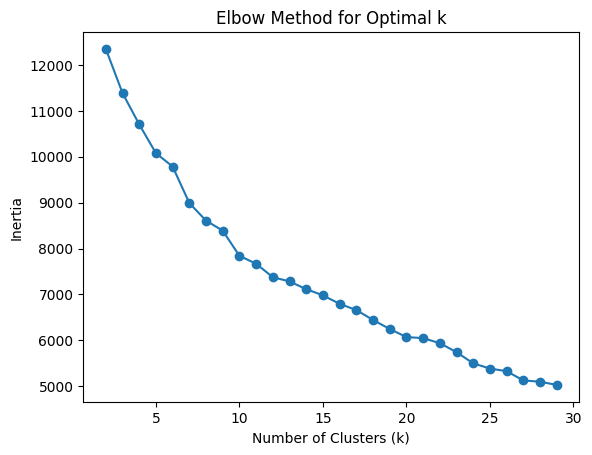

In [70]:
# decide the K value to apply clustering

import matplotlib.pyplot as plt

k_range = range(2,30)  
inertia = []

# Fit KMeans for each k and compute inertia
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(embeddings)
    inertia.append(kmeans.inertia_)
    
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

# inertia > the lower is the better


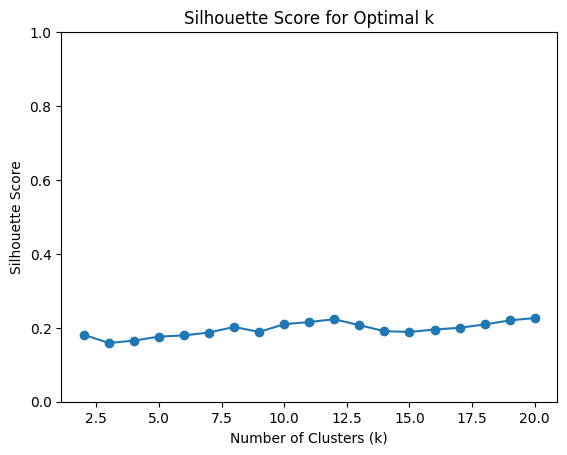

In [71]:
# check  silhouette_score
from sklearn.metrics import silhouette_score

silhouette_scores = []
k_range = range(2, 21) 

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(embeddings)

    if len(set(cluster_labels)) > 1:  
        score = silhouette_score(embeddings, cluster_labels)
        silhouette_scores.append(score)
    else:
        silhouette_scores.append(float('nan'))  

plt.plot(k_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Optimal k')

plt.ylim([0, 1])  
plt.show()

# the higher the better, seems not very good for the given k value range

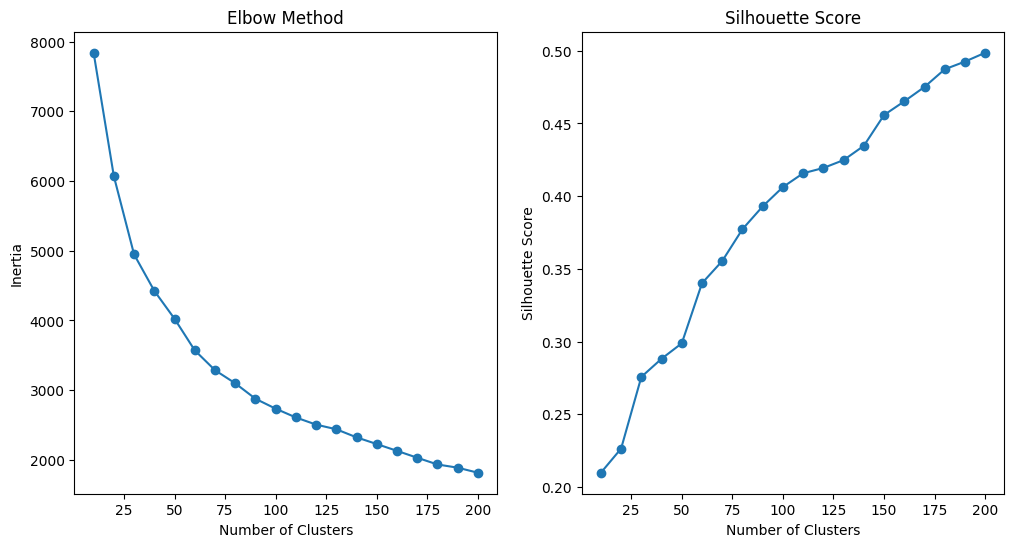

In [72]:
# Test different numbers of clusters, increase the range

inertia = []
sil_scores = []
cluster_range = range(10, 201, 10)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(embeddings)  
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(embeddings, labels))


plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(cluster_range, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(cluster_range, sil_scores, marker='o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()


### Try to Embed Multiple Features for Better Semantic 

In [ ]:
# Changing K score is not relatively effecting the evaluation metrics, embed multiple features not just title
# title is already embedded above
# The  features will improve the semantic search should be related to category> I picked up category and sub category

In [74]:
# Frequency encode the 'category' and 'sub_category' columns(they are categorical values, need to be encoded)
category_freq = df['category'].value_counts()
subcategory_freq = df['sub_category'].value_counts()

df['category_freq_encoded'] = df['category'].map(category_freq)
df['sub_category_freq_encoded'] = df['sub_category'].map(subcategory_freq)

encoded_features = np.column_stack([df['category_freq_encoded'], df['sub_category_freq_encoded']])

In [75]:
# Combine title embeddings with encoded categorical features
combined_features = np.hstack([embeddings, encoded_features])

In [76]:
# Apply PCA to reduce dimensionality
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
reduced_features = pca.fit_transform(combined_features)


In [77]:
# Apply K-Means clustering
kmeans = KMeans(n_clusters=10, random_state=42)  
clusters = kmeans.fit_predict(reduced_features)

# Assign clusters to the DataFrame
df['cluster'] = clusters


In [78]:
# Calculate the Silhouette Score
score = silhouette_score(reduced_features, clusters)
print(f"Silhouette Score: {score}")
# this is a perfect score! Very close to 1 , meaning clusters are almost perfect

Silhouette Score: 0.9932795533093035


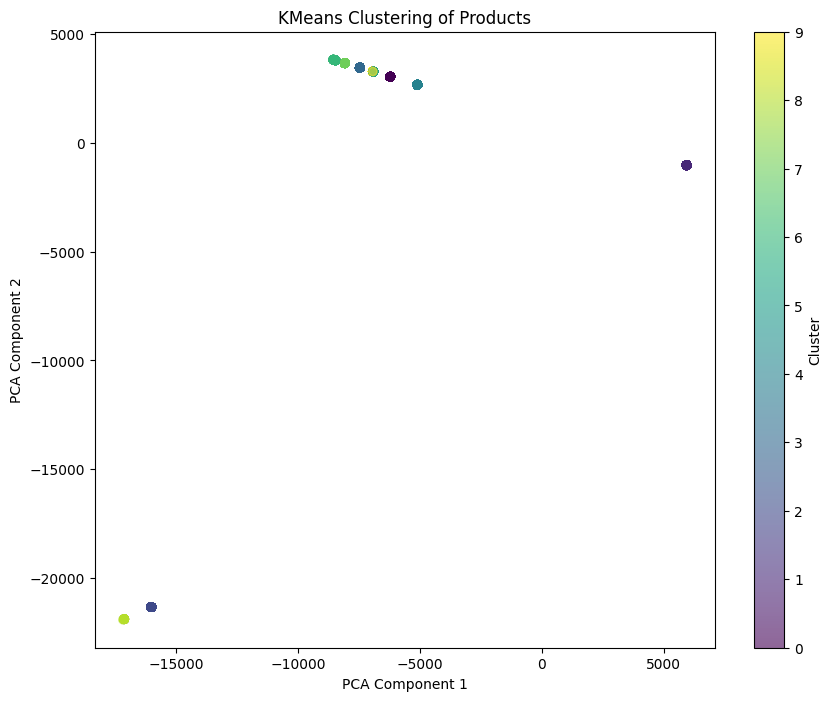

In [79]:
# Apply PCA to reduce `reduced_features` to 2D for visualization
pca = PCA(n_components=2)
reduced_features_2d = pca.fit_transform(reduced_features)

# Plot the clusters
plt.figure(figsize=(10, 8))
plt.scatter(reduced_features_2d[:, 0], reduced_features_2d[:, 1], c=df['cluster'], cmap='viridis', alpha=0.6)
plt.colorbar(label='Cluster')
plt.title('KMeans Clustering of Products')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()



In [80]:
pd.reset_option('display.max_colwidth') #set back to the original setting

In [81]:
# View products in a specific cluster 
cluster_0 = df[df['cluster'] == 0]
cluster_0.head()


,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed,category_freq_encoded,sub_category_freq_encoded,cluster
151,"2,199",3.8,Man,Clothing and Accessories,2021-02-10 20:13:01,All day comfort and support from work to play ...,83% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SWTFYGQ7S4KYESNY,"[{'Color': 'Green'}, {'Fabric': 'Wool Blend'},...",SHAKTICREATION,364,Winter Wear,Striped Collared Neck Casual Men Green Sweater,https://www.flipkart.com/manra-striped-collare...,False,False,False,27127,2495,0
152,"2,199",3.7,Man,Clothing and Accessories,2021-02-10 20:13:01,"MANRA present you stylish wollen ponchos, shaw...",81% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SWTFYHNFFQMQ5PHC,"[{'Color': 'Grey, Black'}, {'Fabric': 'Wool Bl...",SHAKTICREATION,399,Winter Wear,"Striped Collared Neck Casual Men Grey, Black S...",https://www.flipkart.com/manra-striped-collare...,False,False,False,27127,2495,0
153,"2,199",2.6,Man,Clothing and Accessories,2021-02-10 20:13:02,All day comfort and support from work to play ...,79% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SWTFYHP2QQQYEGRJ,"[{'Color': 'Yellow'}, {'Fabric': 'Wool Blend'}...",SHAKTICREATION,453,Winter Wear,Solid V Neck Casual Men Yellow Sweater,https://www.flipkart.com/manra-solid-v-neck-ca...,False,False,False,27127,2495,0
154,"2,199",3.8,Man,Clothing and Accessories,2021-02-10 20:13:02,"MANRA present you stylish wollen ponchos, shaw...",78% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SWTFYGREMHZAR3AG,"[{'Color': 'Maroon'}, {'Fabric': 'Wool Blend'}...",SHAKTICREATION,464,Winter Wear,Striped V Neck Casual Men Maroon Sweater,https://www.flipkart.com/manra-striped-v-neck-...,False,False,False,27127,2495,0
155,"2,199",3.7,Man,Clothing and Accessories,2021-02-10 20:13:03,All day comfort and support from work to play ...,82% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SWTFYGQHYZWGHJ6S,"[{'Color': 'Grey'}, {'Fabric': 'Wool Blend'}, ...",SHAKTICREATION,388,Winter Wear,Striped Collared Neck Casual Men Grey Sweater,https://www.flipkart.com/manra-striped-collare...,False,False,False,27127,2495,0


In [82]:
# Inspect Most frequent categories and sub-categories in each cluster
cluster_category_profile = df.groupby('cluster')['category'].apply(lambda x: x.mode().iloc[0])
cluster_subcategory_profile = df.groupby('cluster')['sub_category'].apply(lambda x: x.mode().iloc[0])

cluster_profiles = pd.concat([cluster_category_profile, cluster_subcategory_profile], axis=1)
cluster_profiles.columns = ['Most Frequent Category', 'Most Frequent Sub-Category']

print(cluster_profiles)

           Most Frequent Category       Most Frequent Sub-Category
cluster                                                           
0        Clothing and Accessories                      Winter Wear
1        Clothing and Accessories                          Topwear
2                        Footwear                   Men's Footwear
3        Clothing and Accessories  Kurtas, Ethnic Sets and Bottoms
4        Clothing and Accessories                       Bottomwear
5        Clothing and Accessories           Innerwear and Swimwear
6        Clothing and Accessories                        Sleepwear
7        Clothing and Accessories                          Fabrics
8           Bags, Wallets & Belts             Bags, Wallet & Belts
9        Clothing and Accessories             Clothing Accessories


In [83]:
cluster_counts = df['cluster'].value_counts()
cluster_counts

cluster
1    15314
4     3667
0     2495
5     1763
9     1743
3     1180
2      920
7      534
6      431
8       42
Name: count, dtype: int64

In [84]:
#pd.reset_option('display.max_colwidth') 

In [85]:
# Display sample product titles for each cluster, to regex them manually
pd.set_option('display.max_colwidth', None)  
for cluster_num in df['cluster'].unique():
    print(f"Cluster {cluster_num}:")
    cluster_titles = df[df['cluster'] == cluster_num]['title'].sample(10)  
    print(cluster_titles)
    print("\n")



Cluster 4:
21045                                                Men Cargos
6250                                        Slim Men Blue Jeans
20180    Regular Fit Men Black Polyester Viscose Blend Trousers
10000                            Solid Men Green Regular Shorts
27466                               Solid Men Black Track Pants
18309                          Solid Men Denim Blue Track Pants
9334          Regular Fit Men Beige Cotton Lycra Blend Trousers
12358                                    Skinny Men Black Jeans
20961                                                Men Cargos
7332            Regular Fit Men Dark Blue Cotton Blend Trousers
Name: title, dtype: object


Cluster 9:
10668               Geometric Print Skull Cap
17524                 Men Peds/Footie/No-Show
18631     Men Solid Ankle Length  (Pack of 6)
18603                Men Low Cut  (Pack of 3)
13932                      Skull ring cap Cap
28143                             Knitted Cap
6895                        Solid

In [ ]:
# Now Inspect Each Cluster Individually With Regex, here a bit of manual work done but clusters were very well close to each other so it made it easy

In [123]:
cluster_4_pattern = r"\b(Jeans|Shorts|Trousers|Track Pants|Cargos|Black Tights|Three Fourths|Harem Pants|Tights)\b"
cluster_9_pattern= r"\b(Tie|Cufflink|Pin|Mid-Calf|Crew|Ankle Length|Calf Length|Cap|Balaclava|Skull|Knee High|Bandana|Hat|Fedora|Handkerchief|Dupatta|Tie|Cravat|Stole|Footie|Low Cut|Hats)\b"
cluster_0_pattern= r"\b(Denim Jacket|Riding Jacket|Gloves|Sweatshirt|Casual Jacket|Sweater|Leather Jacket|Jacket|Sports Jacket|Padded Jacket|Pyjama Set Thermal|Bomber Jacket|Pullover|Cardigan|Varsity Jacket|Shrug|Quilted Jacket|Leg Warmer|Scarf|Gloves|Muffler|Nehru Jacket|Arm Warmer|Top Thermal|Pyjama Thermal|Shawl)\b"
cluster_6_pattern = r"\b(Trousers|Track Suit|Coat|Raincoat|Pyjama|Blazer|Top & Pyjama Set|Waistcoat|Night Suit Set|Suit)\b"
cluster_1_pattern= r"\b(T-Shirt|Casual Shirt|Party Shirt|Formal Shirt|)\b"
cluster_5_pattern= r"\b(Boxer|Vest|Trunks|Brief)\b"
cluster_3_pattern= r"\b(Kurta|Dhoti|Ethnic Dress|Pyjama Set|Suit Set|Pyjama|Sherwani)\b"
cluster_8_pattern= r"\b(Back Suspenders|Fedora)\b"
cluster_2_pattern= r"\b(Slides|Sneakers|Football Shoes|Badminton Shoes|Cricket Shoes|Basketball Shoes|Tennis Shoes|Running Shoes|Canvas Shoes|Walking Shoes|Loafers|Sandal|Casuals|Sports Shoes|Party Wear|Boots|Lace Up|Training & Gym Shoes|COURT SHOE|Kabaddi Shoes|Slip On|Jutis)\b"
cluster_7_pattern= r"\b(Shirt Fabric|Suit Fabric|Kurta Fabric|Trouser Fabric)\b"

#Non-matched Titles Count: 3 (cluster 9) > unidentifiable 
#Non-matched Titles Count: 6 (for cluster 2) >unidentifiable

pd.set_option('display.max_colwidth', None)

In [124]:
# try each cluster with above pattern and add new ones as you see below, run the cell again, until non-matched titles are 0
cluster_num = 9
cluster_titles = df[df['cluster'] == cluster_num]['title']
pattern =  cluster_9_pattern
matches = [title for title in cluster_titles if re.search(pattern, title, re.IGNORECASE)]
non_matches = [title for title in cluster_titles if not re.search(pattern, title, re.IGNORECASE)]
matched_count = len(matches)
non_matched_count = len(non_matches)
print(f"Matched Titles Count: {matched_count}")
print(f"Non-matched Titles Count: {non_matched_count}")
non_matches 

Matched Titles Count: 1740
Non-matched Titles Count: 3


['Men', 'Men', 'Men']

In [171]:
# after making sure catching all keywords, apply this to all data
pattern_all = r"(?i)(Jeans|Shorts|Trousers|Track Pants|Cargos|Black Tights|Three Fourths|Harem Pants|Tights|Tie|Cufflink|Pin|Mid-Calf|Crew|Ankle Length|Calf Length|Cap|Balaclava|Skull|Knee High|Bandana|Hat|Fedora|Handkerchief|Dupatta|Tie|Cravat|Stole|Footie|Low Cut|Hats|Denim Jacket|Gloves|Sweatshirt|Casual Jacket|Sweater|Trousers|Track Suit|Coat|Raincoat|Pyjama|Blazer|Top & Pyjama Set|Waistcoat|Night Suit Set|Suit|T-Shirt|Casual Shirt|Party Shirt|Formal Shirt|Boxer|Vest|Trunks|Brief|Kurta|Dhoti|Ethnic Dress|Pyjama Set|Suit Set|Pyjama|Sherwani|Back Suspenders|Slides|Sneakers|Football Shoes|Badminton Shoes|Cricket Shoes|Basketball Shoes|Tennis Shoes|Running Shoes|Canvas Shoes|Walking Shoes|Loafers|Sandal|Casuals|Sports Shoes|Party Wear|Boots|Lace Up|Training & Gym Shoes|COURT SHOE|Kabaddi Shoes|Slip On|Jutis|Shirt Fabric|Suit Fabric|Kurta Fabric|Trouser Fabric|Scarf|Riding Jacket|Jacket|Pullover|Cardigan|Sports Jacket|Padded Jacket|Pyjama Set Thermal|Bomber Jacket|Pullover|Cardigan|Varsity Jacket|Shrug|Quilted Jacket|Leg Warmer|Scarf|Gloves|Muffler|Nehru Jacket|Arm Warmer|Top Thermal|Pyjama Thermal|Shawl|Sports Shirt|Shirt)"

df['product_category'] = df['title'].str.extract(pattern_all, expand=False)


In [172]:
df["product_category"].isna().sum()
# column 2 and 9 had meaningless titles, inspect manually

9

In [173]:
df['product_category'].value_counts()

product_category
T-Shirt                 11763
Casual Shirt             2518
Sweatshirt               1344
Track Pants              1172
Jeans                     863
Trousers                  752
Shorts                    709
Kurta                     694
Boxer                     600
Vest                      559
Slides                    544
Shirt Fabric              523
Formal Shirt              470
Brief                     436
Dhoti                     388
pin                       364
Mid-Calf                  269
Jacket                    263
Crew                      253
Casual Jacket             236
Pin                       223
Ankle Length              222
Cap                       219
Trunks                    169
Cargos                    157
Balaclava                 144
Tie                       138
Sports Jacket             125
Sweater                   119
Pyjama                    106
Football Shoes            102
Track Suit                 90
Calf Length            

In [175]:
pd.reset_option('display.max_colwidth') # set back to inspect > pd.set_option('display.max_colwidth', None) 

In [177]:
# exctracted from cluster 9 from above function
# poduct details contain socks keyword
df[df['title']=='Men']

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed,category_freq_encoded,sub_category_freq_encoded,cluster,product_category,product_category_2
27097,499,3.7,Pu,Clothing and Accessories,2021-02-11 01:04:17,ECKO Unltd SINGLE JERSEY Cotton Slim Fit BAKED...,60% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SOCDKY7E3925BCAF,"[{'Ideal For': 'Men'}, {'Occasion': 'Sports'},...",Bestrane,199,Clothing Accessories,Men,https://www.flipkart.com/puma-men/p/itm7e17ddd...,False,False,False,27127,1743,9,NaN,
27103,548,3.7,Pu,Clothing and Accessories,2021-02-11 01:04:20,"\r \tConvenient to wear and warm to sport, the...",60% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SOCDKY7E9AC7VCKQ,"[{'Ideal For': 'Men'}, {'Occasion': 'Sports'},...",Bestrane,219,Clothing Accessories,Men,https://www.flipkart.com/puma-men/p/itma2f5a4d...,False,False,False,27127,1743,9,NaN,
28005,499,3.7,Pu,Clothing and Accessories,2021-02-11 01:12:29,\r \tCarry your errands with ease by wearing t...,60% off,[https://rukminim1.flixcart.com/image/128/128/...,False,SOCDKY7EVZ2UGZZ5,"[{'Ideal For': 'Men'}, {'Occasion': 'Sports'},...",wollen store,199,Clothing Accessories,Men,https://www.flipkart.com/puma-men/p/itma124db4...,False,False,False,27127,1743,9,NaN,


In [178]:
# fill nan values
df.loc[df['title'] == 'Men', 'product_category'] = 'socks'

In [179]:
# exctracted from cluster 2
# product details contain school shoes
df[df['title']=='For Men\xa0\xa0(Black)'].head(1)

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed,category_freq_encoded,sub_category_freq_encoded,cluster,product_category,product_category_2
4000,,4.4,Vector,Footwear,2021-02-10 20:52:03,Vector-X is one of the best brands for school ...,,[https://rukminim1.flixcart.com/image/128/128/...,False,SHOF5BDSJGCWN63F,"[{'Color': 'Black'}, {'Outer Material': 'Mesh'...",VIRAJ INTERNATIONAL(Not Enough Ratings)Seller ...,799,Men's Footwear,For Men (Black),https://www.flipkart.com/vector-x-men/p/itmf5b...,False,True,True,920,920,2,NaN,


In [180]:
# Fill na
list_=['For Men\xa0\xa0(Black)',
 'For Men\xa0\xa0(Grey)',
 'For Men\xa0\xa0(Red)',
 'For Men\xa0\xa0(Black)',
 'For Men\xa0\xa0(Black)',
 'For Men\xa0\xa0(Black)']
df.loc[df['title'].isin(list_), 'product_category'] = 'School Shoes'

In [181]:
df[df["product_category"].isna()]
# all product_category filled in now

,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url,is_new_seller,is_not_enough_ratings,is_seller_changed,category_freq_encoded,sub_category_freq_encoded,cluster,product_category,product_category_2


## Drop the Irrelevant Columns and Save the Data

In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 28089 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   actual_price               28089 non-null  object        
 1   average_rating             28089 non-null  object        
 2   brand                      28089 non-null  object        
 3   category                   28089 non-null  object        
 4   crawled_at                 28089 non-null  datetime64[ns]
 5   description                28089 non-null  object        
 6   discount                   28089 non-null  object        
 7   images                     28089 non-null  object        
 8   out_of_stock               28089 non-null  bool          
 9   pid                        28089 non-null  object        
 10  product_details            28089 non-null  object        
 11  seller                     28089 non-null  object        
 12  selling_p

In [185]:
# drop columns created during preprocessing and witg no relevancy for anything
df.drop(["category_freq_encoded","sub_category_freq_encoded","cluster","crawled_at","images"], axis=1, inplace=True)

In [197]:
# save this for the future
df.to_json('preprocessed_data.json', orient='records', lines=True) 

In [188]:
# now create a relevant and computationaly easy datadrame
# Filter the product only in the stock
available_products_df = df[df['out_of_stock'] == False]

In [190]:
#For the second task, redundant features will be dropped.
# Note: This is done tp enable easy embedding and fetching for vector database in the second task. For the actual application, I would keep almost all
# of these features.
# For the second task, I picked up the ones 'defining' the products.
available_products_df.drop(["out_of_stock",'is_new_seller', 'is_not_enough_ratings','is_seller_changed','actual_price', 'average_rating','discount','seller',
       'selling_price','url','brand'],axis=1, inplace=True)


C:\Users\azra_\AppData\Local\Temp\ipykernel_32124\98516473.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  available_products_df.drop(["out_of_stock",'is_new_seller', 'is_not_enough_ratings','is_seller_changed','actual_price', 'average_rating','discount','seller',


In [191]:
available_products_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26445 entries, 0 to 29998
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   category          26445 non-null  object
 1   description       26445 non-null  object
 2   pid               26445 non-null  object
 3   product_details   26445 non-null  object
 4   sub_category      26445 non-null  object
 5   title             26445 non-null  object
 6   product_category  26445 non-null  object
dtypes: object(7)
memory usage: 1.6+ MB


In [196]:
available_products_df.to_json('data_ready.json', orient='records', lines=True)

In [209]:
# Get counts of each category
category_counts = available_products_df['product_category'].value_counts()

# Set a target number of rows per category (e.g., min of categories or any number you prefer)
target_rows_per_category = 10 # You can adjust this based on your dataset

# Create an empty list to store the subsets
balanced_subsets = []

# Loop through the categories and split them
for category, count in category_counts.items():
    category_data = available_products_df[available_products_df['product_category'] == category]
    
    # If category has more rows than the target, we sample down
    if len(category_data) > target_rows_per_category:
        category_data = category_data.sample(n=target_rows_per_category, random_state=42)
    # If category has fewer rows, we keep all rows from that category
    balanced_subsets.append(category_data)

# Combine the subsets into a balanced dataframe
balanced_df = pd.concat(balanced_subsets)

# Shuffle the resulting dataframe to randomize rows
balanced_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)

In [210]:
balanced_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 854 entries, 0 to 853
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   category          854 non-null    object
 1   description       854 non-null    object
 2   pid               854 non-null    object
 3   product_details   854 non-null    object
 4   sub_category      854 non-null    object
 5   title             854 non-null    object
 6   product_category  854 non-null    object
dtypes: object(7)
memory usage: 46.8+ KB


In [212]:
balanced_df["product_category"].value_counts()

product_category
Kurta                   10
Raincoat                10
Footie                  10
Cricket Shoes           10
Shirt Fabric            10
Mid-Calf                10
Slides                  10
Boxer                   10
Trunks                  10
Ethnic Dress            10
Vest                    10
Sweatshirt              10
Tennis Shoes            10
Blazer                  10
Sneakers                10
Sports Jacket           10
Badminton Shoes         10
Muffler                 10
Shorts                  10
pin                     10
Balaclava               10
Bomber Jacket           10
Handkerchief            10
PIN                     10
Jacket                  10
Running Shoes           10
Cargos                  10
Casual Shirt            10
Walking Shoes           10
Three Fourths           10
Tie                     10
Formal Shirt            10
Jeans                   10
Waistcoat               10
Skull                   10
T-Shirt                 10
Dupatta    

In [213]:
balanced_df.to_json('balanced_data.json', orient='records', lines=True)

In [34]:
df.shape

(30000, 17)